# Experimento 16 — YOLO11n com os hiperparâmetros encontrados pelo Optuna no exp15

- Autor: Clésio Gonçalves
- Criado em: 18 nov. 2026

**Objetivo:** repetir o exp08 (YOLO11n sobre os recortes com o macrófago mascarado, batch 16; mAP50 0,485 ± 0,109) usando, em cada fold, os **7 hiperparâmetros que o Optuna escolheu para esse fold no exp15** (YOLO11l; mAP50 0,510 ± 0,115). Não há nova busca.

**Pergunta:** os hiperparâmetros encontrados com o YOLO11l também melhoram o YOLO11n, que treina ~5× mais rápido? Se sim, a busca cara pode ser feita uma vez e reaproveitada nos modelos menores.

**Sem vazamento:** cada fold usa só os parâmetros do **seu próprio** estudo do exp15, escolhidos com a lâmina de validação desse fold. As lâminas de teste do fold nunca participaram da escolha. (Usar um valor único, como a mediana dos 6 folds, misturaria informação das lâminas de validação de outros folds, que são de teste aqui.)

| | |
|---|---|
| **Dataset** | `02_datasets_derivados/03_recortes_512_sem_macrofago/` (o mesmo dos exp08, 09 e 15) |
| **Modelo** | `yolo11n.pt` (2,6M parâmetros), batch 16, imgsz 512 |
| **Hiperparâmetros** | os do exp08, com lr0, weight_decay, hsv_s, hsv_v, degrees, scale e mixup lidos de `exp15_yolo11l_optuna/optuna/melhores_parametros.json` |
| **Bases** | exp08 (mesmo modelo, hiperparâmetros à mão) e exp15 (mesmos hiperparâmetros, YOLO11l) |

## Resultado (18 nov. 2026, 20 minutos)

| | Modelo | Hiperparâmetros | Precisão | Recall | mAP50 | mAP50-95 |
|---|---|---|---|---|---|---|
| **exp16** | YOLO11n | do Optuna (exp15) | 0,525 ± 0,110 | 0,566 ± 0,055 | **0,509 ± 0,109** | 0,196 ± 0,039 |
| exp08 | YOLO11n | à mão | 0,508 ± 0,102 | 0,547 ± 0,074 | 0,485 ± 0,109 | 0,184 ± 0,039 |
| exp15 | YOLO11l | do Optuna | 0,520 ± 0,116 | 0,569 ± 0,064 | 0,510 ± 0,115 | 0,199 ± 0,040 |

- Os parâmetros do exp15 servem para o YOLO11n: mesmo patamar do exp15, em 20 min em vez de 2,5 h.
- +0,024 de mAP50 sobre o exp08 (4 de 6 folds e 6 de 8 lâminas melhores). Ainda abaixo do limiar de ruído, mas é o maior ganho sobre o exp08 nesta série.
- Detalhes por fold e por lâmina no `README.html` desta pasta.

## Utilização da GPU

In [1]:
!nvidia-smi

Wed Nov 18 14:30:05 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 595.99.02              Driver Version: 595.99.02      CUDA Version: 13.2     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 5070 Ti     Off |   00000000:01:00.0  On |                  N/A |
|  0%   48C    P1             48W /  300W |    1310MiB /  16303MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
import os
os.environ["CUDA_DEVICE_ORDER"] = "PCI_BUS_ID"
os.environ["CUDA_VISIBLE_DEVICES"] = "0"


# Importações e parâmetros gerais

In [3]:
import shutil
import yaml
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import cv2
from pathlib import Path
from PIL import Image

import torch
from ultralytics import YOLO

import warnings
warnings.filterwarnings('ignore')

# Bloqueia logs de C++ (INFO e WARNING)
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
os.environ['TF_MLIR_ENABLE_MLIR_HAL_TARGET_ EXECUTABLE_DUMP_PATH'] = ''
os.environ['MLIR_CRASH_REPRODUCER_DIRECTORY'] = ''


In [4]:
# Versões dos pacotes usados neste jupyter notebook
%reload_ext watermark
%watermark -a "Clésio Gonçalves" --iversions
!python --version
!conda -V


Author: Clésio Gonçalves

PIL        : 12.0.0
cv2        : 4.13.0
matplotlib : 3.10.6
numpy      : 2.3.5
pandas     : 2.3.3
torch      : 2.12.1
ultralytics: 8.4.75
yaml       : 6.0.3

Python 3.13.9


conda 26.1.1


In [5]:
torch.cuda.is_available()

True

## Parâmetros do sistema

In [6]:
# Diretório raiz
diretorio_raiz = Path("/mnt/arquivos/Doutorado")


## Estrutura do Dataset

- 8 lâminas anotadas no formato YOLO; recortes 512×512 centrados em macrófagos infectados: recortes 512×512 com a bbox do macrófago pintada de preto (mesmo dataset do exp08).
- Classes do `obj.names` (mantido igual ao original): `0 Non-macrophages`, `1 macrophage` (ausente: região apagada), `2 leishmania` (**alvo**: fora do macrófago), `3 inside-macrophage` (ausente).
- Só a classe `leishmania` é usada, remapeada para o índice `0` (detector de classe única).

![Divisão dos folds por lâmina](../01_preprocessamento/divisao_folds_por_lamina.jpeg)

## Parâmetros do experimento

In [7]:
# Diretório deste experimento (na raiz do projeto)
diretorio_experimento = os.path.join(diretorio_raiz, "05_novos_experimentos", "exp16_yolo11n_params_optuna")

# Dataset: recortes 512×512 com a bbox do macrófago pintada de preto (mesmo dataset do exp08)
# (gerado por 01_preprocessamento/03_mascarar_macrofago_nos_recortes.ipynb)
diretorio_recortes = os.path.join(diretorio_raiz, "02_datasets_derivados", "03_recortes_512_sem_macrofago")

# Tamanho de treino/inferência = tamanho original do recorte, sem upscaling
tamanho_imagem = 512
extensao = '.png'

# Classes do dataset de recortes (mesma ordem do obj.names)
caminho_obj_names = os.path.join(diretorio_recortes, "obj.names")
with open(caminho_obj_names) as f:
    classes_originais = [linha.strip() for linha in f]

# Apenas leishmania FORA do macrófago é a classe de interesse (single-class detector)
nome_classe_interesse = 'leishmania'
indice_classe_interesse = classes_originais.index(nome_classe_interesse)
print(f"Classes originais: {classes_originais}")
print(f"Índice de '{nome_classe_interesse}' (classe de interesse): {indice_classe_interesse}")

# Estrutura YOLO por fold e runs ficam dentro da pasta do experimento
diretorio_yolo_folds = os.path.join(diretorio_experimento, "folds_yolo")
diretorio_runs = os.path.join(diretorio_experimento, "runs")
os.makedirs(diretorio_yolo_folds, exist_ok=True)
os.makedirs(diretorio_runs, exist_ok=True)

# Pesos pré-treinados do YOLO11-nano (cópia local; baixados pela Ultralytics se faltarem)
caminho_pesos_pretreinados = os.path.join(diretorio_experimento, 'yolo11n.pt')
if not os.path.isfile(caminho_pesos_pretreinados):
    caminho_pesos_pretreinados = 'yolo11n.pt'

tamanho_batch = 16

# Hiperparâmetros de treinamento: idênticos ao exp08 (os 7 escolhidos pelo Optuna no exp15 são substituídos por fold)
parametros_treino = dict(
    epochs=150,
    patience=40,
    imgsz=tamanho_imagem,
    batch=tamanho_batch,
    device=0,
    seed=42,
    workers=8,
    cos_lr=True,
    single_cls=True,
    verbose=False,
    optimizer='AdamW',
    lr0=0.0005,
    lrf=0.01,
    # aumento de dados: jitter de cor (imagens em RGB), rotação, flip vertical (sem orientação
    # canônica em microscopia) e mixup; mosaico, flip horizontal, translação e escala seguem o padrão.
    hsv_h=0.03,
    hsv_s=0.9,
    hsv_v=0.6,
    degrees=15.0,
    flipud=0.5,
    mixup=0.1,
)

Classes originais: ['Non-macrophages', 'macrophage', 'leishmania', 'inside-macrophage']
Índice de 'leishmania' (classe de interesse): 2


## Definição dos 6 folds (idêntica aos experimentos anteriores, para comparação direta)

In [8]:
folds = [
    {'fold': 1, 'treino': ['leish_1', 'leish_2', 'leish_7', 'leish_8', 'leish_9'], 'validacao': ['leish_4'], 'teste': ['leish_3', 'leish_5']},
    {'fold': 2, 'treino': ['leish_1', 'leish_3', 'leish_4', 'leish_5', 'leish_9'], 'validacao': ['leish_8'], 'teste': ['leish_2', 'leish_7']},
    {'fold': 3, 'treino': ['leish_2', 'leish_3', 'leish_4', 'leish_5', 'leish_7'], 'validacao': ['leish_9'], 'teste': ['leish_1', 'leish_8']},
    {'fold': 4, 'treino': ['leish_1', 'leish_2', 'leish_3', 'leish_5', 'leish_8'], 'validacao': ['leish_7'], 'teste': ['leish_4', 'leish_9']},
    {'fold': 5, 'treino': ['leish_3', 'leish_4', 'leish_5', 'leish_8', 'leish_9'], 'validacao': ['leish_2'], 'teste': ['leish_1', 'leish_7']},
    {'fold': 6, 'treino': ['leish_3', 'leish_4', 'leish_5', 'leish_7', 'leish_9'], 'validacao': ['leish_1'], 'teste': ['leish_2', 'leish_8']},
]

pd.DataFrame(folds).set_index('fold')


,treino,validacao,teste
fold,,,
1,"[leish_1, leish_2, leish_7, leish_8, leish_9]",[leish_4],"[leish_3, leish_5]"
2,"[leish_1, leish_3, leish_4, leish_5, leish_9]",[leish_8],"[leish_2, leish_7]"
3,"[leish_2, leish_3, leish_4, leish_5, leish_7]",[leish_9],"[leish_1, leish_8]"
4,"[leish_1, leish_2, leish_3, leish_5, leish_8]",[leish_7],"[leish_4, leish_9]"
5,"[leish_3, leish_4, leish_5, leish_8, leish_9]",[leish_2],"[leish_1, leish_7]"
6,"[leish_3, leish_4, leish_5, leish_7, leish_9]",[leish_1],"[leish_2, leish_8]"


## Construção da estrutura de dataset YOLO para cada fold

In [9]:
# Filtra as anotações de um .txt YOLO, mantendo só a classe de interesse e remapeando-a para o índice 0
def remapeia_anotacoes_classe_unica(txt_origem, indice_classe_interesse):
    linhas_novas = []
    if os.path.isfile(txt_origem):
        with open(txt_origem) as f:
            for linha in f:
                linha = linha.strip()
                if not linha:
                    continue
                partes = linha.split()
                if int(partes[0]) == indice_classe_interesse:
                    linhas_novas.append("0 " + " ".join(partes[1:]))
    return linhas_novas


# Cria link simbólico de uma imagem e grava o .txt remapeado (classe única) na pasta de destino
def linka_imagem_e_anotacao(arquivo, pasta_origem, pasta_img_destino, pasta_lbl_destino, indice_classe_interesse):
    nome_base = os.path.splitext(arquivo)[0]

    img_origem = os.path.join(pasta_origem, arquivo)
    img_destino = os.path.join(pasta_img_destino, arquivo)
    if not os.path.exists(img_destino):
        os.symlink(img_origem, img_destino)

    txt_origem = os.path.join(pasta_origem, f"{nome_base}.txt")
    linhas = remapeia_anotacoes_classe_unica(txt_origem, indice_classe_interesse)
    with open(os.path.join(pasta_lbl_destino, f"{nome_base}.txt"), 'w') as f:
        f.write("\n".join(linhas))
        if linhas:
            f.write("\n")


# Monta a estrutura YOLO (images/labels) de um fold: treino, validação, teste (agregado) e teste por lâmina
def monta_dataset_fold(fold, diretorio_recortes, diretorio_yolo_folds, indice_classe_interesse, extensao):
    diretorio_fold = os.path.join(diretorio_yolo_folds, f"fold_{fold['fold']}")
    if os.path.isdir(diretorio_fold):
        shutil.rmtree(diretorio_fold)

    for papel, laminas in [('train', fold['treino']), ('val', fold['validacao']), ('test', fold['teste'])]:
        pasta_img_destino = os.path.join(diretorio_fold, 'images', papel)
        pasta_lbl_destino = os.path.join(diretorio_fold, 'labels', papel)
        os.makedirs(pasta_img_destino, exist_ok=True)
        os.makedirs(pasta_lbl_destino, exist_ok=True)

        for lamina in laminas:
            pasta_origem = os.path.join(diretorio_recortes, lamina)

            if papel == 'test':
                # subpasta individual da lâmina (usada no diagnóstico por lâmina do conjunto de teste)
                pasta_img_lamina = os.path.join(diretorio_fold, 'images', 'test_lamina', lamina)
                pasta_lbl_lamina = os.path.join(diretorio_fold, 'labels', 'test_lamina', lamina)
                os.makedirs(pasta_img_lamina, exist_ok=True)
                os.makedirs(pasta_lbl_lamina, exist_ok=True)

            for arquivo in sorted(os.listdir(pasta_origem)):
                if not arquivo.endswith(extensao):
                    continue
                linka_imagem_e_anotacao(arquivo, pasta_origem, pasta_img_destino, pasta_lbl_destino, indice_classe_interesse)
                if papel == 'test':
                    linka_imagem_e_anotacao(arquivo, pasta_origem, pasta_img_lamina, pasta_lbl_lamina, indice_classe_interesse)

    return diretorio_fold


for fold in folds:
    diretorio_fold = monta_dataset_fold(fold, diretorio_recortes, diretorio_yolo_folds, indice_classe_interesse, extensao)
    n_train = len(os.listdir(os.path.join(diretorio_fold, 'images', 'train')))
    n_val = len(os.listdir(os.path.join(diretorio_fold, 'images', 'val')))
    n_test = len(os.listdir(os.path.join(diretorio_fold, 'images', 'test')))
    print(f"Fold {fold['fold']}: treino={n_train} | validação={n_val} | teste={n_test}")


Fold 1: treino=1064 | validação=126 | teste=378
Fold 2: treino=808 | validação=353 | teste=407


Fold 3: treino=911 | validação=208 | teste=449
Fold 4: treino=954 | validação=280 | teste=334


Fold 5: treino=1065 | validação=127 | teste=376
Fold 6: treino=992 | validação=96 | teste=480


## Geração dos arquivos `data.yaml` por fold

In [10]:
# Grava o data.yaml de um fold. Se 'test_split' for informado, aponta o "test" para uma subpasta específica (lâmina única)
def gera_data_yaml(diretorio_fold, nome_classe, caminho_yaml, test_split='test'):
    conteudo = {
        'path': str(diretorio_fold),
        'train': 'images/train',
        'val': 'images/val',
        'test': f'images/{test_split}',
        'nc': 1,
        'names': {0: nome_classe},
    }
    with open(caminho_yaml, 'w') as f:
        yaml.safe_dump(conteudo, f, sort_keys=False, allow_unicode=True)
    return caminho_yaml


caminhos_yaml = {}        # data.yaml agregado (teste = todas as lâminas do fold)
caminhos_yaml_lamina = {} # data.yaml por lâmina de teste, usado no diagnóstico

for fold in folds:
    n = fold['fold']
    diretorio_fold = os.path.join(diretorio_yolo_folds, f"fold_{n}")

    caminhos_yaml[n] = gera_data_yaml(
        diretorio_fold, nome_classe_interesse,
        os.path.join(diretorio_fold, 'data.yaml'),
    )

    for lamina in fold['teste']:
        caminhos_yaml_lamina[(n, lamina)] = gera_data_yaml(
            diretorio_fold, nome_classe_interesse,
            os.path.join(diretorio_fold, f'data_test_{lamina}.yaml'),
            test_split=f'test_lamina/{lamina}',
        )

print(f"{len(caminhos_yaml)} data.yaml agregados e {len(caminhos_yaml_lamina)} data.yaml por lâmina de teste gerados.")


6 data.yaml agregados e 12 data.yaml por lâmina de teste gerados.


## Hiperparâmetros de cada fold (escolhidos pelo Optuna no exp15)

O exp15 fez uma busca aninhada por fold (8 tentativas × 15 épocas com o YOLO11l, medida só na lâmina de validação). Aqui cada fold usa os **seus** melhores parâmetros, sem nova busca.

In [11]:
import json

caminho_params_exp15 = os.path.join(diretorio_raiz, '05_novos_experimentos', 'exp15_yolo11l_optuna', 'optuna', 'melhores_parametros.json')
with open(caminho_params_exp15) as f:
    melhores_params = {int(k): v for k, v in json.load(f).items()}

# Configuração do exp08 para os mesmos 7 hiperparâmetros, para comparação
parametros_exp08 = dict(lr0=0.0005, weight_decay=0.0005, hsv_s=0.9, hsv_v=0.6, degrees=15.0, scale=0.5, mixup=0.1)

tabela_params = pd.DataFrame(melhores_params).T
tabela_params.index.name = 'fold'
tabela_params.loc['exp08'] = parametros_exp08
tabela_params.round(5)

,lr0,weight_decay,hsv_s,hsv_v,degrees,scale,mixup
fold,,,,,,,
1,0.00010,0.00013,0.20317,0.21762,0.72236,0.59300,0.28754
2,0.00012,0.00010,0.40976,0.69455,29.00892,0.25223,0.00138
3,0.00016,0.00002,0.63917,0.62809,19.50307,0.59629,0.14111
4,0.00027,0.00015,0.21096,0.37696,29.20699,0.36513,0.26714
5,0.00011,0.00002,0.24010,0.53215,29.58638,0.35395,0.29579
6,0.00012,0.00001,0.23176,0.45223,29.85512,0.20472,0.02356
exp08,0.00050,0.00050,0.90000,0.60000,15.00000,0.50000,0.10000


## Treinamento dos 6 folds (YOLO11n, batch 16) com os hiperparâmetros do exp15

Cada fold é treinado do zero com os **seus** hiperparâmetros (`melhores_params[n]`), no mesmo regime do exp08: 150 épocas, patience 40, batch 16. Se o `best.pt` de um fold já existir **e** existir `fold_N/concluido.txt`, o fold é pulado.

In [12]:
caminhos_best = {}

for fold in folds:
    n = fold['fold']
    nome_run = f"fold_{n}"
    caminho_best = os.path.join(diretorio_runs, nome_run, 'weights', 'best.pt')

    marcador = os.path.join(diretorio_runs, nome_run, 'concluido.txt')
    if os.path.isfile(caminho_best) and os.path.isfile(marcador):
        print(f"Fold {n}: pesos já existem em '{caminho_best}'. Treinamento ignorado.")
    else:
        modelo = YOLO(caminho_pesos_pretreinados)
        modelo.train(
            data=caminhos_yaml[n],
            project=diretorio_runs,
            name=nome_run,
            exist_ok=True,
            **{**parametros_treino, **melhores_params[n]},
        )
        with open(marcador, 'w') as f:
            f.write('treino concluído\n')
        print(f"Fold {n}: treinamento concluído. Pesos em '{caminho_best}'.")
        del modelo
        torch.cuda.empty_cache()

    caminhos_best[n] = caminho_best


New https://pypi.org/project/ultralytics/8.4.215 available 😃 Update with 'pip install -U ultralytics'


Ultralytics 8.4.75 🚀 Python-3.13.9 torch-2.12.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Ti, 15819MiB)


engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/mnt/arquivos/Doutorado/05_novos_experimentos/exp16_yolo11n_params_optuna/folds_yolo/fold_1/data.yaml, degrees=0.7223573743289098, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=150, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.03, hsv_s=0.20317281320526664, hsv_v=0.2176198491514595, imgsz=512, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.000101683058075332, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.2875398848069377, mode=train, model=/mnt/arquivos/Doutorado/05_novos_experimentos/exp16_yolo11n_params_optuna/yolo11n.pt, momentum=0.937, m

Overriding class names with single class.


Overriding model.yaml nc=80 with nc=1



                   from  n    params  module                                       arguments                     


... (11,019 outputs left out)

                   all         96        831      0.697      0.584      0.633      0.282


Speed: 0.0ms preprocess, 0.3ms inference, 0.0ms loss, 0.4ms postprocess per image


Results saved to /mnt/arquivos/Doutorado/05_novos_experimentos/exp16_yolo11n_params_optuna/runs/fold_6


Fold 6: treinamento concluído. Pesos em '/mnt/arquivos/Doutorado/05_novos_experimentos/exp16_yolo11n_params_optuna/runs/fold_6/weights/best.pt'.


## Avaliação no conjunto de teste — agregada por fold

In [13]:
# Extrai as métricas de detecção relevantes de um resultado de model.val()
def extrai_metricas(resultado_val):
    rd = resultado_val.results_dict
    return {
        'precisao': rd.get('metrics/precision(B)', float('nan')),
        'recall': rd.get('metrics/recall(B)', float('nan')),
        'mAP50': rd.get('metrics/mAP50(B)', float('nan')),
        'mAP50-95': rd.get('metrics/mAP50-95(B)', float('nan')),
    }


linhas_metricas_fold = []

for fold in folds:
    n = fold['fold']
    modelo = YOLO(caminhos_best[n])
    resultado = modelo.val(data=caminhos_yaml[n], split='test', imgsz=tamanho_imagem, plots=False, verbose=False)

    metricas = extrai_metricas(resultado)
    metricas['fold'] = n
    metricas['laminas_teste'] = ", ".join(fold['teste'])
    linhas_metricas_fold.append(metricas)

df_metricas_fold = pd.DataFrame(linhas_metricas_fold).set_index('fold')
df_metricas_fold = df_metricas_fold[['laminas_teste', 'precisao', 'recall', 'mAP50', 'mAP50-95']]
df_metricas_fold


Ultralytics 8.4.75 🚀 Python-3.13.9 torch-2.12.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Ti, 15819MiB)


YOLO11n summary (fused): 101 layers, 2,582,347 parameters, 0 gradients, 6.3 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3763.2±650.4 MB/s, size: 219.2 KB)


val: Scanning /mnt/arquivos/Doutorado/05_novos_experimentos/exp16_yolo11n_params_optuna/folds_yolo/fold_1/labels/test... 378 images, 52 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 378/378 4.6Kit/s 0.1s

val: New cache created: /mnt/arquivos/Doutorado/05_novos_experimentos/exp16_yolo11n_params_optuna/folds_yolo/fold_1/labels/test.cache


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 4% ──────────── 1/24 2.6it/s 0.1s<9.0s

... (70 outputs left out)

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 30/30 44.6it/s 0.7s

                   all        480       1634      0.411      0.554      0.403      0.157


Speed: 0.2ms preprocess, 0.5ms inference, 0.0ms loss, 0.2ms postprocess per image


,laminas_teste,precisao,recall,mAP50,mAP50-95
fold,,,,,
1,"leish_3, leish_5",0.569491,0.584794,0.568534,0.199208
2,"leish_2, leish_7",0.645020,0.637370,0.640765,0.253274
3,"leish_1, leish_8",0.414923,0.468459,0.372392,0.150887
4,"leish_4, leish_9",0.461588,0.576763,0.472307,0.192682
5,"leish_1, leish_7",0.644904,0.574823,0.596332,0.221924
6,"leish_2, leish_8",0.410957,0.554468,0.403062,0.157306


In [14]:
# Média aritmética e desvio padrão de cada métrica entre os 6 folds
resumo_metricas = df_metricas_fold[['precisao', 'recall', 'mAP50', 'mAP50-95']].agg(['mean', 'std']).T
resumo_metricas.columns = ['média', 'desvio_padrão']
resumo_metricas.round(4)


,média,desvio_padrão
precisao,0.5245,0.1095
recall,0.5661,0.0553
mAP50,0.5089,0.1093
mAP50-95,0.1959,0.0387


## Comparação com os experimentos anteriores

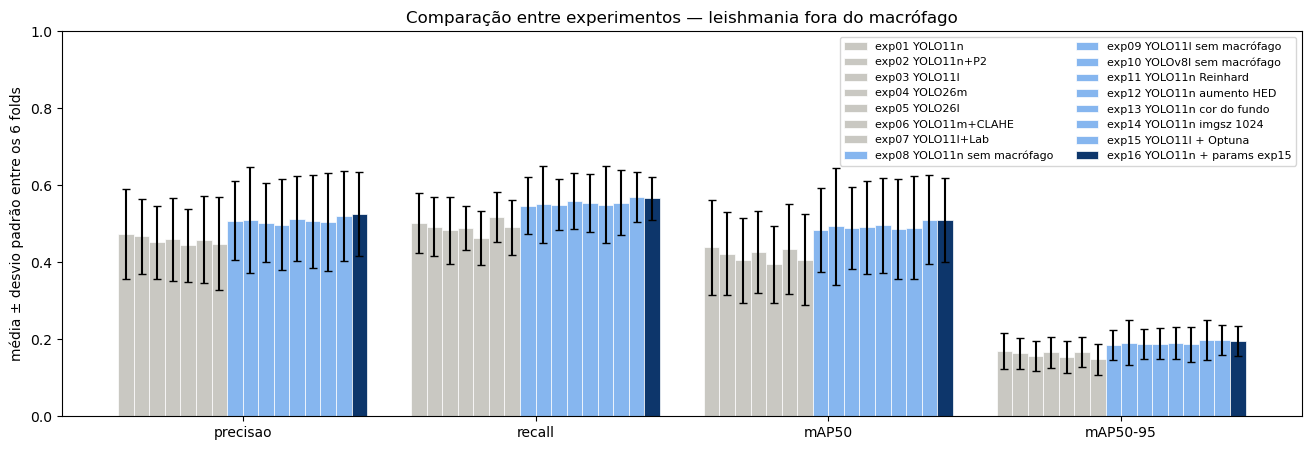

In [15]:
%matplotlib inline
# Médias e desvios padrão dos experimentos anteriores (numeração do resumo_experimentos.html).
# exp01-07: recortes com o macrófago visível; exp08-15: recortes com o macrófago mascarado.
# Bases diretas: exp08 (mesmo modelo, hiperparâmetros à mão) e exp15 (mesmos hiperparâmetros, YOLO11l).
anteriores = {
    'exp01 YOLO11n':               ((0.4735, 0.1164), (0.5012, 0.0780), (0.4391, 0.1229), (0.1695, 0.0457)),
    'exp02 YOLO11n+P2':            ((0.4672, 0.0981), (0.4922, 0.0763), (0.4226, 0.1083), (0.1640, 0.0405)),
    'exp03 YOLO11l':               ((0.4520, 0.0945), (0.4832, 0.0864), (0.4048, 0.1095), (0.1576, 0.0391)),
    'exp04 YOLO26m':               ((0.4595, 0.1079), (0.4894, 0.0567), (0.4272, 0.1068), (0.1659, 0.0396)),
    'exp05 YOLO26l':               ((0.4442, 0.0946), (0.4632, 0.0705), (0.3943, 0.1000), (0.1538, 0.0417)),
    'exp06 YOLO11m+CLAHE':         ((0.4581, 0.1132), (0.5170, 0.0652), (0.4345, 0.1175), (0.1670, 0.0391)),
    'exp07 YOLO11l+Lab':           ((0.4485, 0.1206), (0.4904, 0.0707), (0.4067, 0.1180), (0.1483, 0.0407)),
    'exp08 YOLO11n sem macrófago': ((0.5077, 0.1022), (0.5471, 0.0743), (0.4850, 0.1090), (0.1841, 0.0391)),
    'exp09 YOLO11l sem macrófago': ((0.5098, 0.1364), (0.5508, 0.1003), (0.4930, 0.1516), (0.1915, 0.0588)),
    'exp10 YOLOv8l sem macrófago': ((0.5029, 0.1033), (0.5491, 0.0664), (0.4889, 0.1065), (0.1876, 0.0381)),
    'exp11 YOLO11n Reinhard':      ((0.4980, 0.1182), (0.5595, 0.0720), (0.4915, 0.1207), (0.1885, 0.0408)),
    'exp12 YOLO11n aumento HED':   ((0.5136, 0.1098), (0.5551, 0.0754), (0.4964, 0.1237), (0.1902, 0.0417)),
    'exp13 YOLO11n cor do fundo':  ((0.5064, 0.1207), (0.5500, 0.0994), (0.4875, 0.1298), (0.1866, 0.0465)),
    'exp14 YOLO11n imgsz 1024':    ((0.5053, 0.1276), (0.5543, 0.0842), (0.4892, 0.1339), (0.1985, 0.0518)),
    'exp15 YOLO11l + Optuna':      ((0.5201, 0.1164), (0.5691, 0.0642), (0.5104, 0.1153), (0.1986, 0.0396)),
}
metricas_plot = ['precisao', 'recall', 'mAP50', 'mAP50-95']

nomes_exp = list(anteriores) + ['exp16 YOLO11n + params exp15']
medias_exp = [[m for m, _ in v] for v in anteriores.values()] + [list(resumo_metricas.loc[metricas_plot, 'média'])]
desvios_exp = [[d for _, d in v] for v in anteriores.values()] + [list(resumo_metricas.loc[metricas_plot, 'desvio_padrão'])]

# cinza = macrófago visível; azul claro = mascarado (exp08-15); azul escuro = este experimento
cores = ['#c9c8c2'] * 7 + ['#86b6ef'] * (len(anteriores) - 7) + ['#0d366b']

x = np.arange(len(metricas_plot))
n_exp = len(nomes_exp)
largura = 0.85 / n_exp
fig, ax = plt.subplots(figsize=(16, 5))
for i, (nome, media, desvio) in enumerate(zip(nomes_exp, medias_exp, desvios_exp)):
    deslocamento = (i - (n_exp - 1) / 2) * largura
    ax.bar(x + deslocamento, media, largura, yerr=desvio, capsize=3, label=nome, color=cores[i], edgecolor='white', linewidth=0.5)

ax.set_xticks(x)
ax.set_xticklabels(metricas_plot)
ax.set_ylim(0, 1)
ax.set_ylabel('média ± desvio padrão entre os 6 folds')
ax.set_title('Comparação entre experimentos — leishmania fora do macrófago')
ax.legend(loc='upper right', fontsize=8, ncol=2)
plt.show()

## Diagnóstico por lâmina (conjunto de teste)

In [16]:
linhas_metricas_lamina = []

for (n, lamina), caminho_yaml_lamina in caminhos_yaml_lamina.items():
    modelo = YOLO(caminhos_best[n])
    resultado = modelo.val(data=caminho_yaml_lamina, split='test', imgsz=tamanho_imagem, plots=False, verbose=False)

    metricas = extrai_metricas(resultado)
    metricas['fold'] = n
    metricas['lamina'] = lamina
    linhas_metricas_lamina.append(metricas)

df_metricas_lamina = pd.DataFrame(linhas_metricas_lamina)[['lamina', 'fold', 'precisao', 'recall', 'mAP50', 'mAP50-95']]
df_metricas_lamina.sort_values(['lamina', 'fold']).reset_index(drop=True)


Ultralytics 8.4.75 🚀 Python-3.13.9 torch-2.12.1+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Ti, 15819MiB)


YOLO11n summary (fused): 101 layers, 2,582,347 parameters, 0 gradients, 6.3 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3358.8±325.6 MB/s, size: 219.9 KB)


val: Scanning /mnt/arquivos/Doutorado/05_novos_experimentos/exp16_yolo11n_params_optuna/folds_yolo/fold_1/labels/test_lamina/leish_3... 17 images, 11 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 17/17 5.2Kit/s 0.0s

val: New cache created: /mnt/arquivos/Doutorado/05_novos_experimentos/exp16_yolo11n_params_optuna/folds_yolo/fold_1/labels/test_lamina/leish_3.cache


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 20.6it/s 0.1s

... (118 outputs left out)

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 23/23 44.7it/s 0.5s

                   all        353        992      0.402      0.533      0.402      0.157


Speed: 0.2ms preprocess, 0.5ms inference, 0.0ms loss, 0.2ms postprocess per image


,lamina,fold,precisao,recall,mAP50,mAP50-95
0,leish_1,3,0.630572,0.507822,0.552495,0.244148
1,leish_1,5,0.694378,0.430806,0.536983,0.236989
2,leish_2,2,0.425207,0.481308,0.363721,0.138604
3,leish_2,6,0.431209,0.571651,0.420563,0.164675
4,leish_3,1,0.506375,0.400000,0.391920,0.146656
5,leish_4,4,0.316748,0.287879,0.186768,0.083924
6,leish_5,1,0.573948,0.588148,0.571587,0.200327
7,leish_7,2,0.707682,0.688212,0.715988,0.285718
8,leish_7,5,0.676216,0.640356,0.659446,0.239490
9,leish_8,3,0.404470,0.498992,0.378109,0.147012


In [17]:
# Resumo por lâmina: média e desvio padrão entre as vezes em que a lâmina caiu no teste (1 ou 2 folds)
resumo_lamina = df_metricas_lamina.groupby('lamina')[['precisao', 'recall', 'mAP50', 'mAP50-95']].agg(['mean', 'std', 'count'])
resumo_lamina.round(4)


precisao                recall                 mAP50                \
            mean     std count    mean     std count    mean     std count   
lamina                                                                       
leish_1   0.6625  0.0451     2  0.4693  0.0545     2  0.5447  0.0110     2   
leish_2   0.4282  0.0042     2  0.5265  0.0639     2  0.3921  0.0402     2   
leish_3   0.5064     NaN     1  0.4000     NaN     1  0.3919     NaN     1   
leish_4   0.3167     NaN     1  0.2879     NaN     1  0.1868     NaN     1   
leish_5   0.5739     NaN     1  0.5881     NaN     1  0.5716     NaN     1   
leish_7   0.6919  0.0223     2  0.6643  0.0338     2  0.6877  0.0400     2   
leish_8   0.4034  0.0015     2  0.5161  0.0242     2  0.3898  0.0166     2   
leish_9   0.5060     NaN     1  0.6232     NaN     1  0.5354     NaN     1   

        mAP50-95                
            mean     std count  
lamina                          
leish_1   0.2406  0.0051     2  
leish_2   0.1516  0.0184     2  
leish_3   0.1467     NaN     1  
leish_4   0.0839     NaN     1  
leish_5   0.2003     NaN     1  
leish_7   0.2626  0.0327     2  
leish_8   0.1520  0.0070     2  
leish_9   0.2171     NaN     1

## Comparação visual: anotação do especialista vs. detecção da YOLO

Em cada imagem: caixas **amarelas** = anotação original do especialista (classe `leishmania`, remapeada); caixas **vermelhas** = detecções do modelo (com confiança). Amostras da lâmina com melhor e da lâmina com pior mAP50 no diagnóstico acima. Imagens em RGB puro (região do macrófago aparece preta, mascarada no pré-processamento).

In [18]:
# Lê as caixas (em pixels) de um .txt YOLO (classe única já remapeada)
def le_boxes_pixel(txt_path, largura, altura):
    boxes = []
    if os.path.isfile(txt_path):
        with open(txt_path) as f:
            for linha in f:
                linha = linha.strip()
                if not linha:
                    continue
                _, xc, yc, w, h = map(float, linha.split())
                boxes.append((xc * largura, yc * altura, w * largura, h * altura))
    return boxes


# Desenha, sobre o mesmo eixo, as caixas do especialista (amarelo) e as detecções do modelo (vermelho)
def desenha_comparacao(eixo, caminho_imagem, caminho_label, modelo, conf=0.25):
    img_bgr = cv2.imread(caminho_imagem)
    altura, largura = img_bgr.shape[:2]
    eixo.imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))

    gt_boxes = le_boxes_pixel(caminho_label, largura, altura)
    for xc, yc, w, h in gt_boxes:
        eixo.add_patch(patches.Rectangle((xc - w / 2, yc - h / 2), w, h, linewidth=1.5, edgecolor='yellow', facecolor='none'))

    resultado = modelo.predict(caminho_imagem, conf=conf, imgsz=tamanho_imagem, verbose=False)[0]
    for caixa in resultado.boxes:
        x1, y1, x2, y2 = caixa.xyxy[0].tolist()
        confianca = float(caixa.conf[0])
        eixo.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, linewidth=1.5, edgecolor='red', facecolor='none'))
        eixo.text(x1, max(y1 - 4, 0), f"{confianca:.2f}", color='red', fontsize=7, va='bottom')

    eixo.set_title(f"{os.path.basename(caminho_imagem)}\nespecialista={len(gt_boxes)} | YOLO={len(resultado.boxes)}", fontsize=8)
    eixo.axis('off')


def fold_para_lamina(lamina):
    for fold in folds:
        if lamina in fold['teste']:
            return fold['fold']


Melhor lâmina (mAP50): leish_7 | Pior lâmina (mAP50): leish_4


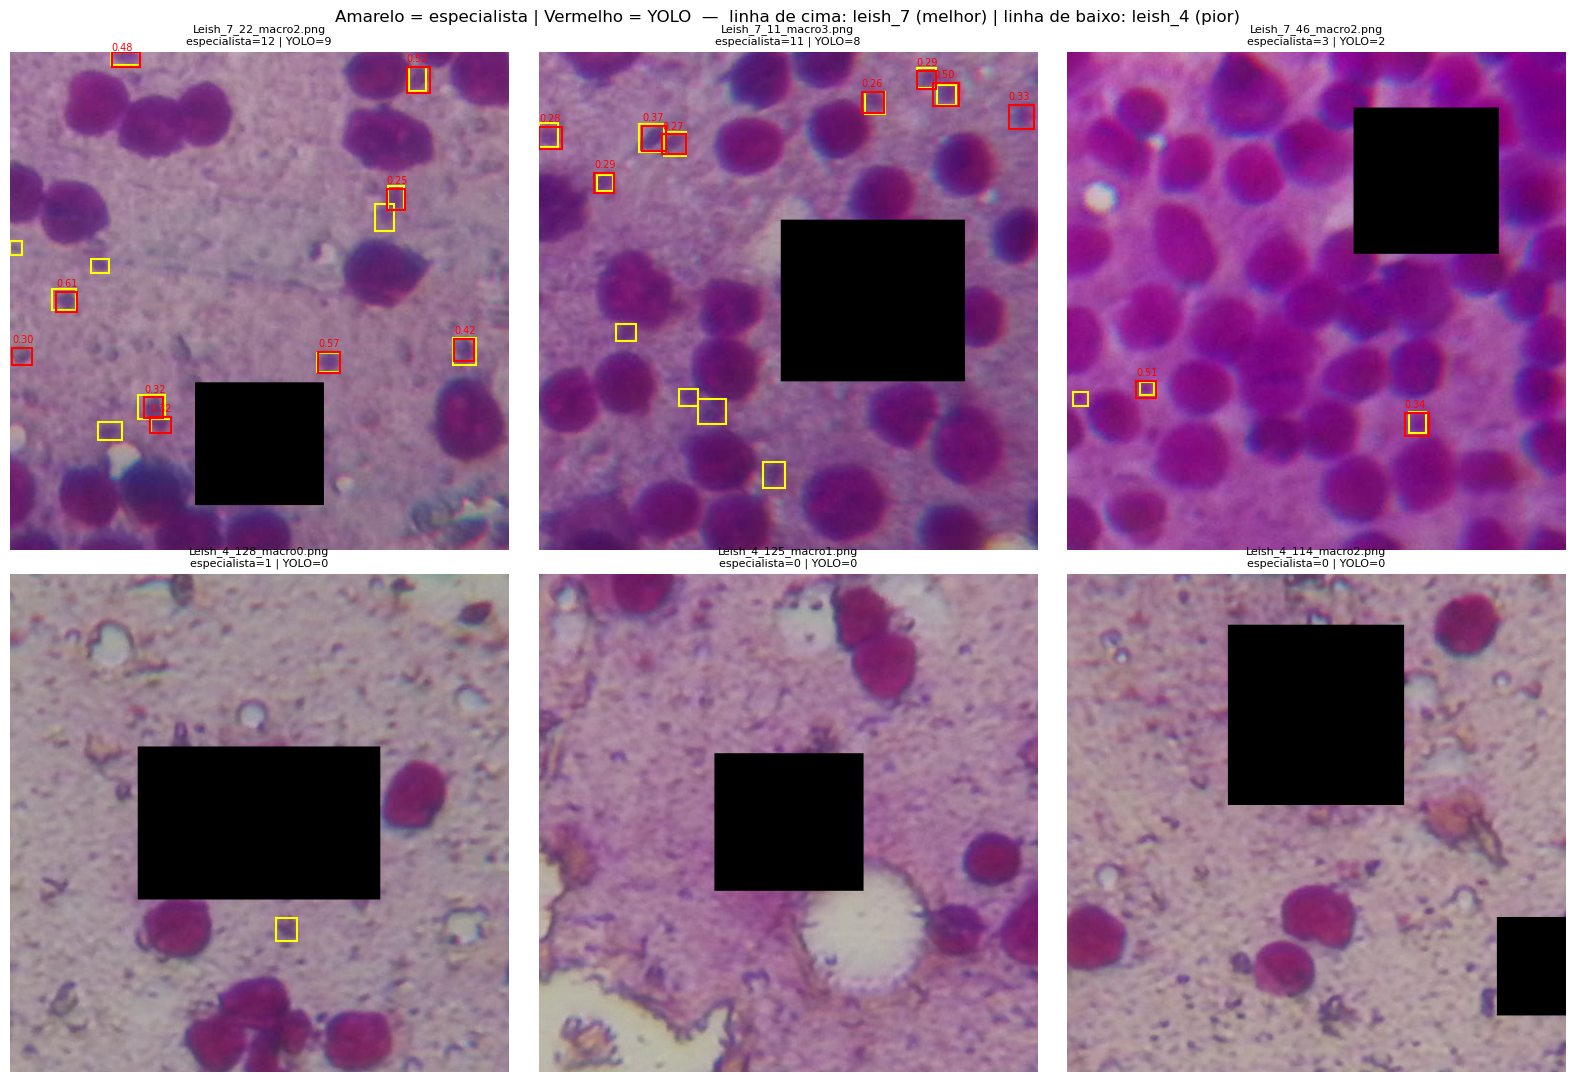

In [19]:
%matplotlib inline
melhor_lamina = resumo_lamina[('mAP50', 'mean')].idxmax()
pior_lamina = resumo_lamina[('mAP50', 'mean')].idxmin()
print(f"Melhor lâmina (mAP50): {melhor_lamina} | Pior lâmina (mAP50): {pior_lamina}")

cache_modelos = {}
def obter_modelo(n_fold):
    if n_fold not in cache_modelos:
        cache_modelos[n_fold] = YOLO(caminhos_best[n_fold])
    return cache_modelos[n_fold]

amostras_comparacao = []
random.seed(42)
for lamina in [melhor_lamina, pior_lamina]:
    n_fold = fold_para_lamina(lamina)
    pasta_img = os.path.join(diretorio_yolo_folds, f"fold_{n_fold}", 'images', 'test_lamina', lamina)
    pasta_lbl = os.path.join(diretorio_yolo_folds, f"fold_{n_fold}", 'labels', 'test_lamina', lamina)
    imagens = sorted(f for f in os.listdir(pasta_img) if f.endswith(extensao))
    escolhidas = random.sample(imagens, min(3, len(imagens)))
    for img_nome in escolhidas:
        amostras_comparacao.append((n_fold, lamina, pasta_img, pasta_lbl, img_nome))

fig, eixos = plt.subplots(2, 3, figsize=(16, 11))
for eixo, (n_fold, lamina, pasta_img, pasta_lbl, img_nome) in zip(eixos.ravel(), amostras_comparacao):
    modelo = obter_modelo(n_fold)
    nome_base = os.path.splitext(img_nome)[0]
    desenha_comparacao(eixo, os.path.join(pasta_img, img_nome), os.path.join(pasta_lbl, f"{nome_base}.txt"), modelo)

fig.suptitle(f"Amarelo = especialista | Vermelho = YOLO  —  linha de cima: {melhor_lamina} (melhor) | linha de baixo: {pior_lamina} (pior)")
plt.tight_layout()
plt.show()
